
# Install Dependencies

Gerekli Kütüphanelerin Kurulumu

In [1]:
%pip install numpy pandas scikit-learn matplotlib seaborn catboost

  Using cached numpy-2.2.6-cp310-cp310-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached pandas-2.3.3-cp310-cp310-macosx_11_0_arm64.whl.metadata (91 kB)
  Using cached scikit_learn-1.7.2-cp310-cp310-macosx_12_0_arm64.whl.metadata (11 kB)
  Using cached matplotlib-3.10.9-cp310-cp310-macosx_11_0_arm64.whl.metadata (52 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
  Using cached graphviz-0.21-py3-none-any.whl.metadata (12 kB)
  Using cached plotly-7.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
  Using cached narwhals-2.28.0-py3-none-any.whl.metadata (15 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 5.9 MB/s  0:00:00 eta 0:00:01
   

# Import Libraries

Kütüphanelerin İçe Aktarımı

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from catboost import CatBoostRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import seaborn as sns

%matplotlib inline

# Load Data

Veirilerin CSV Dosyadan Yüklenmesi

In [3]:
df = pd.read_csv('datasets/Salary_Data.csv')
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   object 
 2   Education Level      6701 non-null   object 
 3   Job Title            6702 non-null   object 
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), object(3)
memory usage: 314.4+ KB


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


Veri seti 6706 örneklemden oluşuyor. 6 feature var. Bunların 5i tahmin edici değişken, 1i ise hedef değişken. Hedef değişkenimiz salary. <br><br>

Age, Years of Experience ve Salary değişkenleri float64 tipinde. <br>
Gender, Country ve Education Level değişkenleri ise object tipinde. <br>

# Exploratory Data Analysis

Veri Seti keşfi

In [4]:
print(f"Dataset Shape: {df.shape}")
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Dataset Shape: (6704, 6)
Number of Rows: 6704
Number of Columns: 6


In [5]:
display(df.head(10))
display(df.tail(10))

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0
5,29.0,Male,Bachelor's,Marketing Analyst,2.0,55000.0
6,42.0,Female,Master's,Product Manager,12.0,120000.0
7,31.0,Male,Bachelor's,Sales Manager,4.0,80000.0
8,26.0,Female,Bachelor's,Marketing Coordinator,1.0,45000.0
9,38.0,Male,PhD,Senior Scientist,10.0,110000.0


,Age,Gender,Education Level,Job Title,Years of Experience,Salary
6694,27.0,Male,High School,Digital Marketing Manager,2.0,40000.0
6695,33.0,Female,Bachelor's Degree,Content Marketing Manager,7.0,90000.0
6696,28.0,Male,PhD,Sales Representative,4.0,55000.0
6697,51.0,Female,Master's Degree,Senior Product Marketing Manager,19.0,190000.0
6698,37.0,Male,Bachelor's Degree,Junior Sales Representative,6.0,75000.0
6699,49.0,Female,PhD,Director of Marketing,20.0,200000.0
6700,32.0,Male,High School,Sales Associate,3.0,50000.0
6701,30.0,Female,Bachelor's Degree,Financial Manager,4.0,55000.0
6702,46.0,Male,Master's Degree,Marketing Manager,14.0,140000.0
6703,26.0,Female,High School,Sales Executive,1.0,35000.0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   object 
 2   Education Level      6701 non-null   object 
 3   Job Title            6702 non-null   object 
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), object(3)
memory usage: 314.4+ KB


Veride null değerler var <br>


In [7]:
display(df.describe())

,Age,Years of Experience,Salary
count,6702.000000,6701.000000,6699.000000
mean,33.620859,8.094687,115326.964771
std,7.614633,6.059003,52786.183911
min,21.000000,0.000000,350.000000
25%,28.000000,3.000000,70000.000000
50%,32.000000,7.000000,115000.000000
75%,38.000000,12.000000,160000.000000
max,62.000000,34.000000,250000.000000


salary kısmında 350 değeri min değer olarak görünüyor. Demek ki aykırı değerler olabilir.<br>

## Missing Values

Eksik değer tespiti

In [8]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": df.isnull().mean() * 100
})

display(missing)

,Missing Count,Missing Percentage
Age,2,0.029833
Gender,2,0.029833
Education Level,3,0.044749
Job Title,2,0.029833
Years of Experience,3,0.044749
Salary,5,0.074582


5 salary örnekleminde null değer var. Bunlar silinmeli tahmin yapılamayacağından. <br>
Kalan her satırda 2-3 null değer var. Bunlar ise doldurulabilir. <br>

## Duplicate Rows

Tekrarlayan satırların tespiti

In [9]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 4912


4912 tane tekrarlayan satır var. Bunlar silinmeli. <br>
Aksi takdirde data leakage oluşabilir. <br>

## Unique Values

In [10]:
for column in df.columns:
    print(f"\n{column}")
    print("Unique Values:", df[column].nunique())
    print(df[column].unique()[:10])


Age
Unique Values: 41
[32. 28. 45. 36. 52. 29. 42. 31. 26. 38.]

Gender
Unique Values: 3
['Male' 'Female' nan 'Other']

Education Level
Unique Values: 7
["Bachelor's" "Master's" 'PhD' nan "Bachelor's Degree" "Master's Degree"
 'High School' 'phD']

Job Title
Unique Values: 193
['Software Engineer' 'Data Analyst' 'Senior Manager' 'Sales Associate'
 'Director' 'Marketing Analyst' 'Product Manager' 'Sales Manager'
 'Marketing Coordinator' 'Senior Scientist']

Years of Experience
Unique Values: 37
[ 5.  3. 15.  7. 20.  2. 12.  4.  1. 10.]

Salary
Unique Values: 444
[ 90000.  65000. 150000.  60000. 200000.  55000. 120000.  80000.  45000.
 110000.]


Age feature'ında 41 farklı değer var. <br>
Gender feature'ında 3 farklı değer var. Ve nan değer var. <br>
Education Level feature'ında 7 farklı değer var ama isimden kaynaklı unique değerler var. <br>
Job Title feature'ında 193 farklı değer var. Bunlar üzerinde işlem yapılması gerekiyor. <br>
Salary feature'ında 444 farklı değer var. <br>

## Numerical distributions

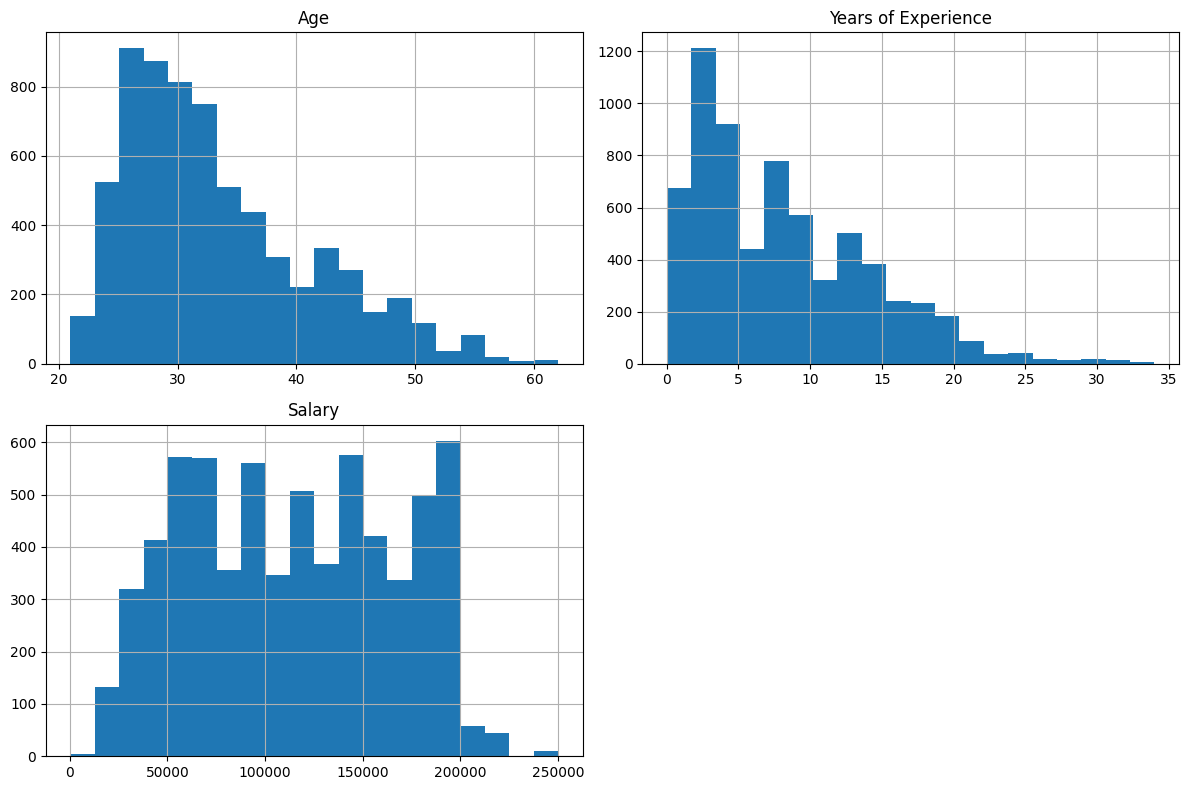

In [11]:
df.hist(figsize=(12, 8), bins=20)
plt.tight_layout()
plt.show()

Age özniteliği 22-34 arasında yoğunlaşmış. </br>
Experience özniteliği 0-5 arasında. </br>
Salary ise dengeli bir şekilde dağılmış. En uçta aykırı değerler var.</br>


## Outliers

Outlier tespiti

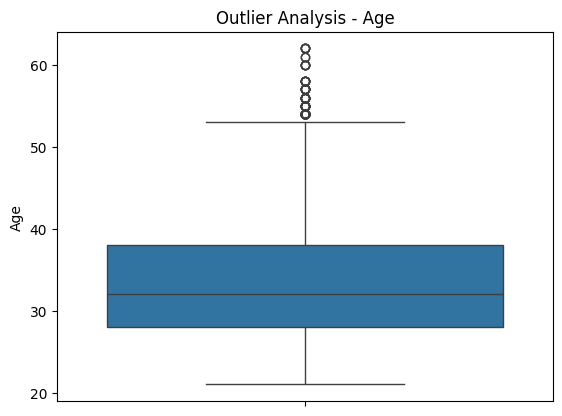

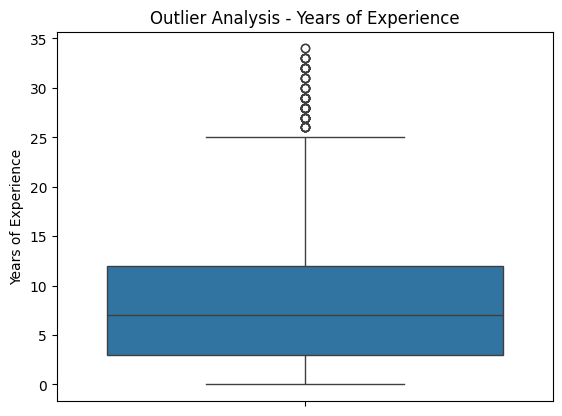

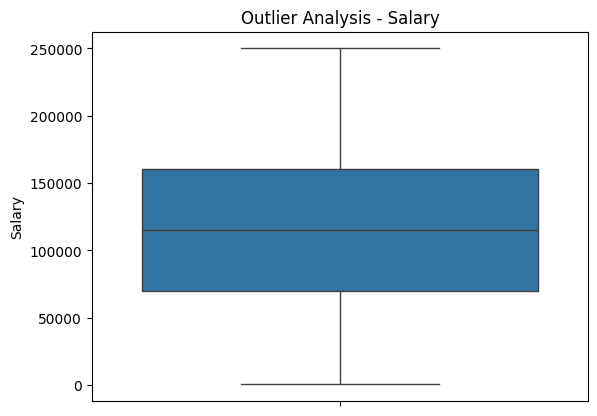

In [12]:
for column in df.select_dtypes(include=np.number).columns:
    sns.boxplot(data=df[column])
    plt.xticks(rotation=45)
    plt.title(f"Outlier Analysis - {column}")
    plt.show()



## Korrelation Matrix

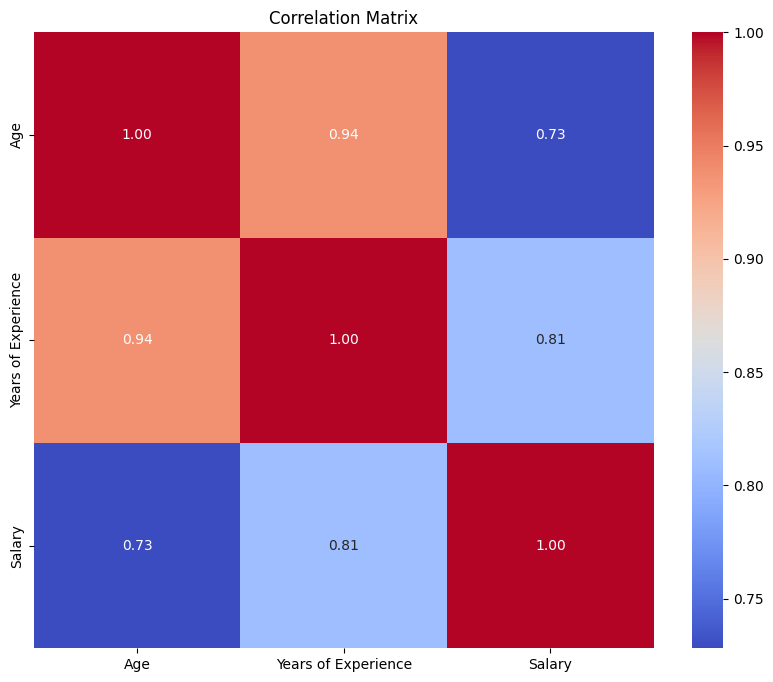

In [13]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix")
plt.show()

Year of Experience ve Age değişkenleri arasında yüksek korelasyon var. <br>

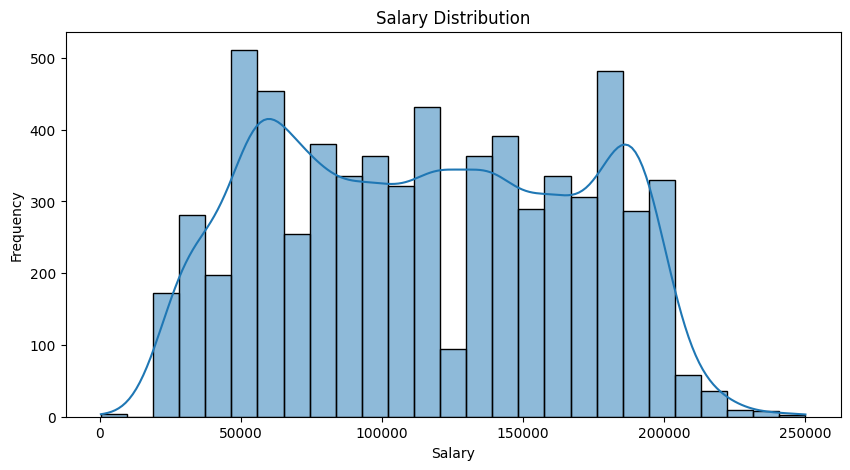

In [14]:
plt.figure(figsize=(10, 5))

sns.histplot(df["Salary"], kde=True)

plt.title("Salary Distribution")
plt.xlabel("Salary")
plt.ylabel("Frequency")

plt.show()

# Data Cleaning

Veri temizleme işlemleri

In [15]:
print(df.dtypes)
df.info()

Age                    float64
Gender                  object
Education Level         object
Job Title               object
Years of Experience    float64
Salary                 float64
dtype: object
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6702 non-null   float64
 1   Gender               6702 non-null   object 
 2   Education Level      6701 non-null   object 
 3   Job Title            6702 non-null   object 
 4   Years of Experience  6701 non-null   float64
 5   Salary               6699 non-null   float64
dtypes: float64(3), object(3)
memory usage: 314.4+ KB


## Renaming Column Names

Sütun isimlerini daha rahat kullanılabilir hale getirmek için yeniden adlandırma işlemi yapılacak. <br>

In [16]:
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "_")
)
print(df.columns)

Index(['age', 'gender', 'education_level', 'job_title', 'years_of_experience',
       'salary'],
      dtype='object')


### Removing Rows without Salary

salary feature'ında null değerler var. Bunlar modelin eğitilmesinde bir getirisi olmadığından silinmeli. <br>

In [17]:
df = df.dropna(subset=["salary"]).copy()

### Normalize Categorical Text

In [18]:
for column in ["gender", "job_title", "education_level"]:
    df[column] = (
        df[column]
        .astype("string")
        .str.strip()
    )

education_mapping = {
    "Bachelor's Degree": "Bachelor's",
    "Master's Degree": "Master's",
    "phD": "PhD"
}

df["education_level"] = (
    df["education_level"]
    .replace(education_mapping)
)
print(df.columns.tolist())

['age', 'gender', 'education_level', 'job_title', 'years_of_experience', 'salary']


bazı aynı değerler farklı şekillerde yazılmış. Bunlar normalize edilip tek bir değer haline getirilmesi gerekiyor.

## Duplicate Values

Tekrarlayan satırların tespiti ve silinmesi

In [19]:
duplicate_count = df.duplicated().sum()

print("Duplicate Rows:", duplicate_count)

display(df[df.duplicated(keep=False)].sort_values(by=df.columns.tolist()))

Duplicate Rows: 4912


,age,gender,education_level,job_title,years_of_experience,salary
4884,21.0,Female,High School,Junior Sales Representative,0.0,25000.0
4897,21.0,Female,High School,Junior Sales Representative,0.0,25000.0
4910,21.0,Female,High School,Junior Sales Representative,0.0,25000.0
4923,21.0,Female,High School,Junior Sales Representative,0.0,25000.0
4936,21.0,Female,High School,Junior Sales Representative,0.0,25000.0
...,...,...,...,...,...,...
1225,62.0,Male,PhD,Software Engineer Manager,19.0,200000.0
1258,62.0,Male,PhD,Software Engineer Manager,19.0,200000.0
1305,62.0,Male,PhD,Software Engineer Manager,19.0,200000.0
1236,62.0,Male,PhD,Software Engineer Manager,20.0,200000.0


Çok fazla tekrarlayan satır var. Bunların data leakage oluşmaması için silinmesi gerekiyor. <br>

In [20]:
df = df.drop_duplicates().reset_index(drop=True)

print("Duplicate Rows after removal:", df.duplicated().sum())
print(f"New Dataset Shape: {df.shape}")

Duplicate Rows after removal: 0
New Dataset Shape: (1787, 6)


Duplicate satırlar kaldırıldığında geriye 1787 örneklem kalıyor. <br>

## Missing Values

Eksik verilerin belirlenmesi

In [21]:
missing_analysis = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_analysis)

,Missing_Count,Missing_Percentage
age,0,0.00
gender,0,0.00
education_level,1,0.06
job_title,0,0.00
years_of_experience,0,0.00
salary,0,0.00


sadece education_level feature'unda null değer var. Bu değer örneklem sayısı çok az olduğundan silinmesi yerine doldurulması daha doğru olur. <br>

In [22]:
for line in df.iterrows():
    if line[1].isnull().values.any():
        print(f"Row {line[0]} has missing values: {line[1].isnull().values.sum()}")

Row 670 has missing values: 1


### Cleaning Empty Rows

Boş satırların temizlenmesi

In [23]:
missing_per_row = df.isna().sum(axis=1)
rows_to_drop = missing_per_row[missing_per_row > 5].index

print(f"Rows to drop: {len(rows_to_drop)}")

Rows to drop: 0


boş satır yok

In [24]:
df = df.drop(rows_to_drop)
print(f"New Dataset Shape: {df.shape}")

New Dataset Shape: (1787, 6)


# Dataset Splitting

Veri setinin eğitim ve test setlerine ayrılması <br>
Oran 80-20 olacak şekilde ayarlanacak. <br>

In [25]:
X = df.drop(columns=["salary"])
y = df["salary"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)


Train: (1429, 5)
Test: (358, 5)


Veriler bölündükten sonra 1429 train ve 358 test örneklemi var.

# Preprocessing

Veriyi ön işleme

In [26]:
numeric_features = [
    "age",
    "years_of_experience"
]

nominal_features = [
    "gender",
    "job_title"
]

ordinal_features = [
    "education_level"
]

### Filling Missing Valuee in Education Level Column

1 eksik değer vardı o da education level column'unda. 

In [27]:
column_names = X_train.columns.tolist()

for line in X_train.iterrows():
    if line[1].isnull().values.any():
        columns_with_missing = [column_names[i] for i, is_null in enumerate(line[1].isnull().values) if is_null]
        print(f"Dataset: X_train, Row {line[0]} has missing values in columns: {columns_with_missing}")

column_names = X_test.columns.tolist()
for line in X_test.iterrows():
    if line[1].isnull().values.any():
        columns_with_missing = [column_names[i] for i, is_null in enumerate(line[1].isnull().values) if is_null]
        print(f"Dataset: X_test, Row {line[0]} has missing values in columns: {columns_with_missing}")

Dataset: X_test, Row 670 has missing values in columns: ['education_level']


Eksik veri test verisindeymiş

In [28]:
mfv_education_level = X_train['education_level'].mode()[0]

print("Most common education level:", mfv_education_level)

X_train['education_level'] = X_train['education_level'].fillna(mfv_education_level)
X_test['education_level'] = X_test['education_level'].fillna(mfv_education_level)

print("X_train empty values:", X_train['education_level'].isnull().sum())
print("X_test empty values:", X_test['education_level'].isnull().sum())

X_train.info()
X_test.info()

Most common education level: Bachelor's
X_train empty values: 0
X_test empty values: 0
<class 'pandas.core.frame.DataFrame'>
Index: 1429 entries, 175 to 1126
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  1429 non-null   float64
 1   gender               1429 non-null   string 
 2   education_level      1429 non-null   string 
 3   job_title            1429 non-null   string 
 4   years_of_experience  1429 non-null   float64
dtypes: float64(2), string(3)
memory usage: 67.0 KB
<class 'pandas.core.frame.DataFrame'>
Index: 358 entries, 538 to 1435
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   age                  358 non-null    float64
 1   gender               358 non-null    string 
 2   education_level      358 non-null    string 
 3   job_title            358 non-null    string 
 4   y

Train verisinde en çok görülen değer olan "Bachelor's" olduğu öğrenildi. <br>
Data leakage oluşmaması için test verisindeki eksik değer de "Bachelor's" ile dolduruldu. <br>

## Categorical Columns Processing

In [29]:
categorical_columns = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(X_train[column].value_counts(dropna=False))


--- gender ---
gender
Male      779
Female    646
Other       4
Name: count, dtype: Int64

--- education_level ---
education_level
Bachelor's     627
Master's       438
PhD            277
High School     87
Name: count, dtype: Int64

--- job_title ---
job_title
Software Engineer Manager    110
Full Stack Engineer           99
Senior Software Engineer      79
Senior Project Engineer       73
Back end Developer            64
                            ... 
Principal Engineer             1
Creative Director              1
Senior IT Consultant           1
Junior Designer                1
VP of Operations               1
Name: count, Length: 174, dtype: Int64


### Label Encoding

"Gender" ve "Job Title" sütunları nominal kategorik değişkenlerdir, bu yüzden bu sütunlar için one-hot encoding kullanacağız.<br>

"Education Level" sütunu ordinal kategorik bir değişkendir, bu yüzden bu sütun için label encoding kullanacağız.<br>

#### Gender

In [30]:
X_train = pd.get_dummies(
    X_train,
    columns=["gender"],
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=["gender"],
    drop_first=True,
    dtype=int
)

Train ve test kısmına pd.get_dummies() ile one-hot encoding uygulandı. <br>
drop_first=True ile ilk sütun düşürüldü. <br>

In [31]:
X_train.columns

Index(['age', 'education_level', 'job_title', 'years_of_experience',
       'gender_Male', 'gender_Other'],
      dtype='object')

gender yerine artık gender_Male ve gender_other sütunları var. <br>

In [32]:
X_train.head(10)

,age,education_level,job_title,years_of_experience,gender_Male,gender_Other
175,42.0,PhD,Senior Marketing Manager,18.0,0,0
631,35.0,Bachelor's,Full Stack Engineer,8.0,0,0
1084,26.0,Bachelor's,Back end Developer,2.0,1,0
481,49.0,PhD,Software Engineer Manager,15.0,1,0
1565,32.0,Master's,Software Engineer,9.0,0,0
1608,45.0,Master's,Sales Manager,8.0,0,0
756,36.0,Master's,Front end Developer,8.0,1,0
1054,42.0,Bachelor's,Back end Developer,16.0,1,0
450,31.0,Bachelor's,Software Engineer,9.0,1,0
198,49.0,Master's,Director of Human Capital,21.0,0,0


#### Job Title

job_title
Software Engineer Manager    127
Full Stack Engineer          122
Senior Software Engineer      96
Senior Project Engineer       95
Back end Developer            81
                            ... 
Financial Advisor              1
Junior Designer                1
Chief Technology Officer       1
Technical Recruiter            1
Delivery Driver                1
Name: count, Length: 192, dtype: Int64


<Axes: xlabel='job_title', ylabel='count'>

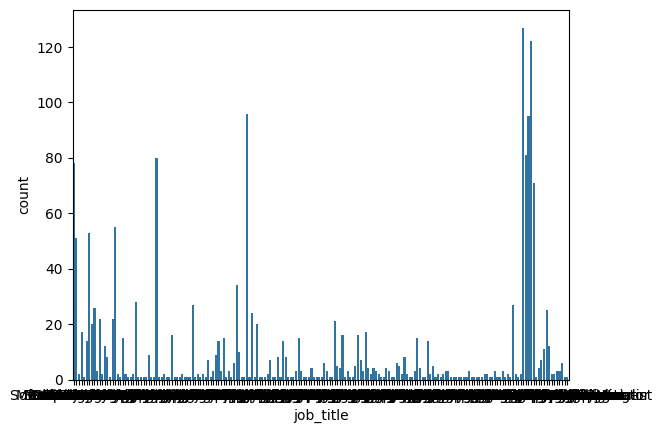

In [33]:
freq = df["job_title"].value_counts()
print(freq)

sns.countplot(data=df, x='job_title')

In [34]:
job_titles = df['job_title'].unique()

for title in job_titles:
    print(f"\n--- {title} ---")
    print(df[df['job_title'] == title]['job_title'].value_counts())


--- Software Engineer ---
job_title
Software Engineer    78
Name: count, dtype: Int64

--- Data Analyst ---
job_title
Data Analyst    51
Name: count, dtype: Int64

--- Senior Manager ---
job_title
Senior Manager    2
Name: count, dtype: Int64

--- Sales Associate ---
job_title
Sales Associate    17
Name: count, dtype: Int64

--- Director ---
job_title
Director    1
Name: count, dtype: Int64

--- Marketing Analyst ---
job_title
Marketing Analyst    14
Name: count, dtype: Int64

--- Product Manager ---
job_title
Product Manager    53
Name: count, dtype: Int64

--- Sales Manager ---
job_title
Sales Manager    20
Name: count, dtype: Int64

--- Marketing Coordinator ---
job_title
Marketing Coordinator    26
Name: count, dtype: Int64

--- Senior Scientist ---
job_title
Senior Scientist    3
Name: count, dtype: Int64

--- Software Developer ---
job_title
Software Developer    22
Name: count, dtype: Int64

--- HR Manager ---
job_title
HR Manager    2
Name: count, dtype: Int64

--- Financial A

Çok yoğun kategoriler var ve çok nadir olanlar da var. Az olanların tamamına other demek yerine meslekleri türlerine göre gruplamak daha doğru olur. <br>

In [35]:
labels = {}

for title in job_titles:
    title = title.strip().lower().split()

    for word in title:
        if word not in labels:
            labels[word] = 1
        else:
            labels[word] += 1
labels = dict(sorted(labels.items(), key=lambda item: item[1], reverse=True))

print("Job Title Labels:", labels)

Job Title Labels: {'senior': 50, 'manager': 44, 'junior': 36, 'marketing': 21, 'analyst': 20, 'director': 20, 'of': 14, 'specialist': 14, 'operations': 13, 'sales': 12, 'coordinator': 12, 'engineer': 11, 'software': 10, 'data': 10, 'developer': 10, 'hr': 10, 'product': 9, 'business': 9, 'designer': 9, 'scientist': 8, 'financial': 8, 'project': 8, 'human': 8, 'resources': 7, 'customer': 6, 'it': 6, 'support': 5, 'social': 5, 'media': 5, 'development': 5, 'generalist': 4, 'ux': 4, 'account': 4, 'representative': 4, 'research': 4, 'associate': 3, 'service': 3, 'recruiter': 3, 'consultant': 3, 'accountant': 3, 'technical': 3, 'digital': 3, 'web': 3, 'advisor': 3, 'end': 3, 'rep': 2, 'vp': 2, 'success': 2, 'executive': 2, 'copywriter': 2, 'finance': 2, 'graphic': 2, 'researcher': 2, 'content': 2, 'chief': 2, 'officer': 2, 'principal': 2, 'supply': 2, 'chain': 2, 'training': 2, 'front': 2, 'juniour': 2, 'entry': 1, 'clerk': 1, 'ceo': 1, 'writer': 1, 'network': 1, 'administrative': 1, 'assist

içinde geçen kelimeleri bir dict'e çevirip meslek keyword'ları çıkarılması

In [36]:
job_groups = {
    "engineering": [
        "engineer", "developer", "software", "programmer",
        "architect", "devops", "network", "system"
    ],

    "data": [
        "data", "analyst", "scientist", "machine learning",
        "business intelligence", "statistician"
    ],

    "management": [
        "manager", "director", "chief", "executive",
        "supervisor", "president", "lead"
    ],

    "marketing": [
        "marketing", "seo", "content", "brand",
        "digital marketing", "social media"
    ],

    "sales": [
        "sales", "account executive", "account manager",
        "business development", "representative"
    ],

    "hr": [
        "human resources", "hr", "recruiter",
        "talent acquisition", "people"
    ],

    "design": [
        "designer", "design", "ux", "ui",
        "graphic", "creative"
    ],

    "other": []
}

def map_job_title(job_title):
    if pd.isna(job_title):
        return "other"
    job_title = str(job_title).lower()
    for group_name, keywords in job_groups.items():
        if any(keyword in job_title for keyword in keywords):
            return group_name
    return "other"

job_title_mapping = {
    job_title: map_job_title(job_title)
    for job_title in X_train["job_title"].dropna().unique()
}

print(pd.Series(job_title_mapping).value_counts())

management     57
other          29
data           27
engineering    23
hr             11
design         10
marketing      10
sales           7
Name: count, dtype: int64


en optimal olacak şekilde benzer meslekler birleştirildi. Şimdi job_title sütununda 8 farklı değer var. <br>

In [37]:
X_train["job_title"] = X_train["job_title"].map(job_title_mapping).fillna("other")
X_test["job_title"] = X_test["job_title"].map(
    lambda title: job_title_mapping.get(title, map_job_title(title))
)

In [38]:
print(f"X_train Job Title Value Counts:\n{X_train['job_title'].value_counts()}")

X_train Job Title Value Counts:
job_title
engineering    631
management     380
data           194
sales           67
hr              57
marketing       41
other           39
design          20
Name: count, dtype: int64


##### One-Hot Encoding for Job Title Column

yapılan kategori azaltma işlemlerinden sonra artık One-hot encoding uygulanabilir. <br>

In [39]:
X_train = pd.get_dummies(
    X_train,
    columns=["job_title"],
    drop_first=True,
    dtype=int
)

X_test = pd.get_dummies(
    X_test,
    columns=["job_title"],
    drop_first=True,
    dtype=int
)

In [40]:
X_train.info()
X_train.head(10)

<class 'pandas.core.frame.DataFrame'>
Index: 1429 entries, 175 to 1126
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   age                    1429 non-null   float64
 1   education_level        1429 non-null   string 
 2   years_of_experience    1429 non-null   float64
 3   gender_Male            1429 non-null   int64  
 4   gender_Other           1429 non-null   int64  
 5   job_title_design       1429 non-null   int64  
 6   job_title_engineering  1429 non-null   int64  
 7   job_title_hr           1429 non-null   int64  
 8   job_title_management   1429 non-null   int64  
 9   job_title_marketing    1429 non-null   int64  
 10  job_title_other        1429 non-null   int64  
 11  job_title_sales        1429 non-null   int64  
dtypes: float64(2), int64(9), string(1)
memory usage: 145.1 KB


,age,education_level,years_of_experience,gender_Male,gender_Other,job_title_design,job_title_engineering,job_title_hr,job_title_management,job_title_marketing,job_title_other,job_title_sales
175,42.0,PhD,18.0,0,0,0,0,0,1,0,0,0
631,35.0,Bachelor's,8.0,0,0,0,1,0,0,0,0,0
1084,26.0,Bachelor's,2.0,1,0,0,1,0,0,0,0,0
481,49.0,PhD,15.0,1,0,0,1,0,0,0,0,0
1565,32.0,Master's,9.0,0,0,0,1,0,0,0,0,0
1608,45.0,Master's,8.0,0,0,0,0,0,1,0,0,0
756,36.0,Master's,8.0,1,0,0,1,0,0,0,0,0
1054,42.0,Bachelor's,16.0,1,0,0,1,0,0,0,0,0
450,31.0,Bachelor's,9.0,1,0,0,1,0,0,0,0,0
198,49.0,Master's,21.0,0,0,0,0,0,1,0,0,0


encoding yapıldıktan sonra sütun sayısı 12 ye çıktı

### Education Level

In [41]:
df.education_level.unique()

<StringArray>
['Bachelor's', 'Master's', 'PhD', <NA>, 'High School']
Length: 5, dtype: string

ordinal encoding yapılması için listeye çevrildi. <br> 
Liste 0 dan son öğeye doğru sıralandı. <br>

In [42]:
levels = ["nan", "High School", "Bachelor's", "Master's", "PhD"]

ordinal_encoder = OrdinalEncoder(categories=[levels], dtype=int)
X_train['education_level'] = ordinal_encoder.fit_transform(X_train[['education_level']])
X_test['education_level'] = ordinal_encoder.transform(X_test[['education_level']])

In [43]:
X_train.head(10)

,age,education_level,years_of_experience,gender_Male,gender_Other,job_title_design,job_title_engineering,job_title_hr,job_title_management,job_title_marketing,job_title_other,job_title_sales
175,42.0,4,18.0,0,0,0,0,0,1,0,0,0
631,35.0,2,8.0,0,0,0,1,0,0,0,0,0
1084,26.0,2,2.0,1,0,0,1,0,0,0,0,0
481,49.0,4,15.0,1,0,0,1,0,0,0,0,0
1565,32.0,3,9.0,0,0,0,1,0,0,0,0,0
1608,45.0,3,8.0,0,0,0,0,0,1,0,0,0
756,36.0,3,8.0,1,0,0,1,0,0,0,0,0
1054,42.0,2,16.0,1,0,0,1,0,0,0,0,0
450,31.0,2,9.0,1,0,0,1,0,0,0,0,0
198,49.0,3,21.0,0,0,0,0,0,1,0,0,0


artık education_level sütununda 0-4 arası değerler var

In [44]:
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

print("Train columns:", X_train.shape[1])
print("Test columns:", X_test.shape[1])

print(
    "Columns match:",
    X_train.columns.equals(X_test.columns)
)

Train columns: 12
Test columns: 12
Columns match: True


Encodingler sonrası train ve test sütun sayıları eşitlenmesinin kontrol edilmesi

# Outlier Detection

In [45]:
numeric_columns = [
    "age",
    "years_of_experience",
    "salary"
]

## IQR

In [46]:
outlier_results = []

for column in numeric_columns:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Feature": column,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": len(outliers) / len(df) * 100
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary.round(2))

,Feature,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,29.0,41.0,12.0,11.0,59.0,6,0.34
1,years_of_experience,3.0,13.0,10.0,-12.0,28.0,22,1.23
2,salary,70000.0,160000.0,90000.0,-65000.0,295000.0,0,0.00


## Z-Score

In [47]:
from scipy.stats import zscore

for column in numeric_columns:

    z_scores = np.abs(zscore(df[column].dropna()))

    outlier_count = (z_scores > 3).sum()

    print(f"{column}: {outlier_count} outliers")

age: 6 outliers
years_of_experience: 16 outliers
salary: 0 outliers


# Scaling

verilerin ölçeklenmesi

In [48]:
scaling_columns = [
    "age",
    "years_of_experience"
]

scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[scaling_columns] = scaler.fit_transform(X_train[scaling_columns])
X_test_scaled[scaling_columns] = scaler.transform(X_test[scaling_columns])

Age ve Years of Experience sütunları için StandardScaler kullanılıp değerler -1 ile 1 arasında ölçeklendirildi. <br>

In [49]:
X_train_scaled.head(10)

,age,education_level,years_of_experience,gender_Male,gender_Other,job_title_design,job_title_engineering,job_title_hr,job_title_management,job_title_marketing,job_title_other,job_title_sales
175,0.810667,4,1.263823,0,0,0,0,0,1,0,0,0
631,-0.031750,2,-0.180113,0,0,0,1,0,0,0,0,0
1084,-1.114857,2,-1.046474,1,0,0,1,0,0,0,0,0
481,1.653084,4,0.830642,1,0,0,1,0,0,0,0,0
1565,-0.392785,3,-0.035719,0,0,0,1,0,0,0,0,0
1608,1.171703,3,-0.180113,0,0,0,0,0,1,0,0,0
756,0.088596,3,-0.180113,1,0,0,1,0,0,0,0,0
1054,0.810667,2,0.975036,1,0,0,1,0,0,0,0,0
450,-0.513131,2,-0.035719,1,0,0,1,0,0,0,0,0
198,1.653084,3,1.697003,0,0,0,0,0,1,0,0,0


# Training Model

Modellerin Eğitilmesi

## Linear Regression

In [50]:
linear_model = LinearRegression()

linear_model.fit(X_train_scaled, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [51]:
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

In [52]:
X_test.head(10)

,age,education_level,years_of_experience,gender_Male,gender_Other,job_title_design,job_title_engineering,job_title_hr,job_title_management,job_title_marketing,job_title_other,job_title_sales
538,38.0,3,10.0,1,0,0,1,0,0,0,0,0
1146,44.0,4,12.0,0,0,0,0,0,1,0,0,0
1350,28.0,1,2.0,1,0,0,0,1,0,0,0,0
289,36.0,2,8.0,1,0,0,0,0,0,0,0,0
1765,42.0,2,13.0,1,0,0,0,0,1,0,0,0
1061,45.0,4,21.0,0,0,0,1,0,0,0,0,0
682,34.0,3,9.0,1,0,0,1,0,0,0,0,0
585,33.0,3,5.0,0,0,0,1,0,0,0,0,0
1491,26.0,2,2.0,0,0,1,0,0,0,0,0,0
1647,27.0,1,3.0,0,0,0,0,0,0,0,0,1


In [53]:
y_pred = linear_model.predict(X_test_scaled)

In [54]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Linear Regression Model Results")
print("--------------------------------")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Linear Regression Model Results
--------------------------------
MAE  : 20373.48
MSE  : 720295404.10
RMSE : 26838.32
R²   : 0.7295


Linear Regression Model Results
--------------------------------
MAE  : 20373.48<br>
MSE  : 720295404.10<br>
RMSE : 26838.32<br>
R²   : 0.7295<br><br><br>


Modelin R² değeri 0.7295 çıktı. Bu değer modelin veriyi açıklama oranını gösterir. Yani model verinin %72.95'ini açıklayabiliyor. <br><br>
MAE değeri 20373.48 çıktı. Bu değer modelin tahmin ettiği değer ile gerçek değer arasındaki farkın ortalamasını gösterir. Yani modelin tahmin ettiği değer ile gerçek değer arasındaki fark ortalama olarak 20373.48 birimdir. <br><br>
MSE değeri 720295404.10 çıktı. Bu değer modelin tahmin ettiği değer ile gerçek değer arasındaki farkın karesinin ortalamasını gösterir. Yani modelin tahmin ettiği değer ile gerçek değer arasındaki farkın karesinin ortalaması 720295404.10 birimdir. <br><br>

RMSE değeri 26838.32 çıktı. Bu değer modelin tahmin ettiği değer ile gerçek değer arasındaki farkın karekökünün ortalamasını gösterir. Yani modelin tahmin ettiği değer ile gerçek değer arasındaki farkın karekökünün ortalaması 26838.32 birimdir. <br><br>

Genel olarak modelin R² değeri yüksek, MAE, MSE ve RMSE değerleri düşük olduğu için modelin performansı normal olarak değerlendirilebilir. <br><br>



In [55]:
comparison = pd.DataFrame({
    "Actual Salary": y_test,
    "Predicted Salary": y_pred
})

print(comparison.head(10))

      Actual Salary  Predicted Salary
538        155000.0     128658.214483
1146       120000.0     141180.015736
1350        43000.0      35081.007416
289         95000.0     115574.422290
1765       130000.0     125880.286638
1061       181285.0     188837.015424
682        150000.0     122312.441519
585        120000.0     101125.753541
1491        50000.0      47198.141909
1647        40000.0      34876.871398


gerçek değerler ile tahmin edilen değerlerin karşılaştırılması 

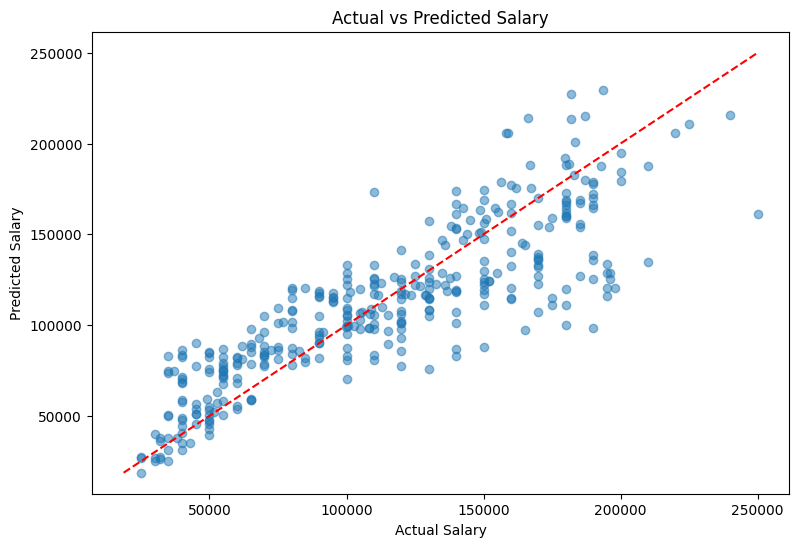

In [56]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    color="red"
)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")
plt.show()

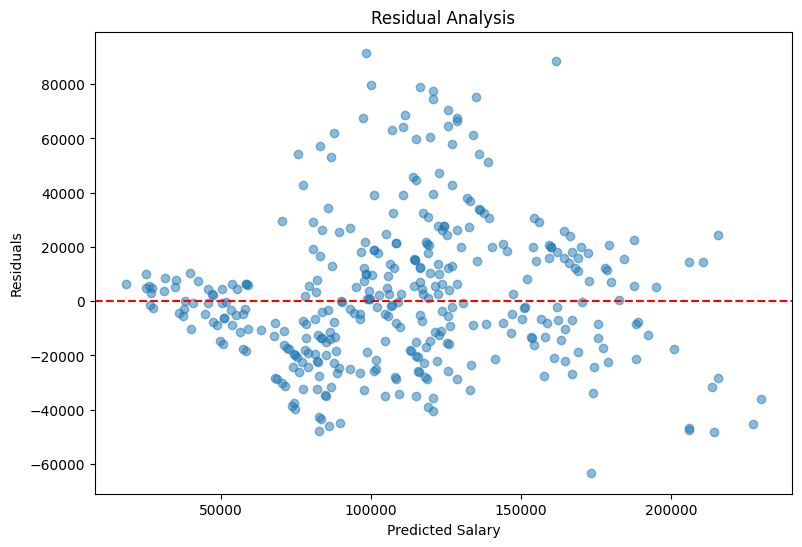

In [57]:
residuals = y_test - y_pred

plt.figure(figsize=(9, 6))

plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Salary")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.show()

## Random Forest Regressor

Random Forest Modelinin Eğitilmesi

In [58]:
random_forest_model = RandomForestRegressor(n_estimators=100, random_state=42)

random_forest_model.fit(X_train_scaled, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


n_estimators=100 olarak ayarlandı. Bu değer modelin kaç tane karar ağacı oluşturacağını belirler. <br>

In [59]:
y_pred = random_forest_model.predict(X_test_scaled)

In [60]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Random Forest Regression Model Results")
print("--------------------------------")
print(f"MAE  : {mae:.2f}")
print(f"MSE  : {mse:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"R²   : {r2:.4f}")

Random Forest Regression Model Results
--------------------------------
MAE  : 13666.49
MSE  : 398453873.69
RMSE : 19961.31
R²   : 0.8504


Random Forest Regression Model Results
--------------------------------
MAE  : 13666.49<br>
MSE  : 398453873.69<br>
RMSE : 19961.31<br>
R²   : 0.8504<br><br><br>

Modelin R² değeri 0.8504 çıktı. Linear Regression modeline göre daha yüksek bir R² değeri elde edildi. Bu da modelin veriyi daha iyi açıkladığını gösterir. <br><br>
MAE değeri Linear Regression modeline göre çok daha düşük çıktı. Bu da modelin tahmin ettiği değer ile gerçek değer arasındaki farkın daha az olduğunu gösterir. <br><br>

Genel olarak modelin R² değeri yüksek, MAE, MSE ve RMSE değerleri düşük olduğu için modelin performansı Linear Regression modeline göre daha iyi olarak değerlendirilebilir. <br><br>

In [61]:
comparison = pd.DataFrame({
    "Actual Salary": y_test,
    "Predicted Salary": y_pred
})

print(comparison.head(10))

      Actual Salary  Predicted Salary
538        155000.0     145708.040000
1146       120000.0     124900.000000
1350        43000.0      37753.333333
289         95000.0      86497.619048
1765       130000.0     129420.000000
1061       181285.0     174089.986405
682        150000.0     128480.856167
585        120000.0     103273.333333
1491        50000.0      56991.428571
1647        40000.0      50105.000000


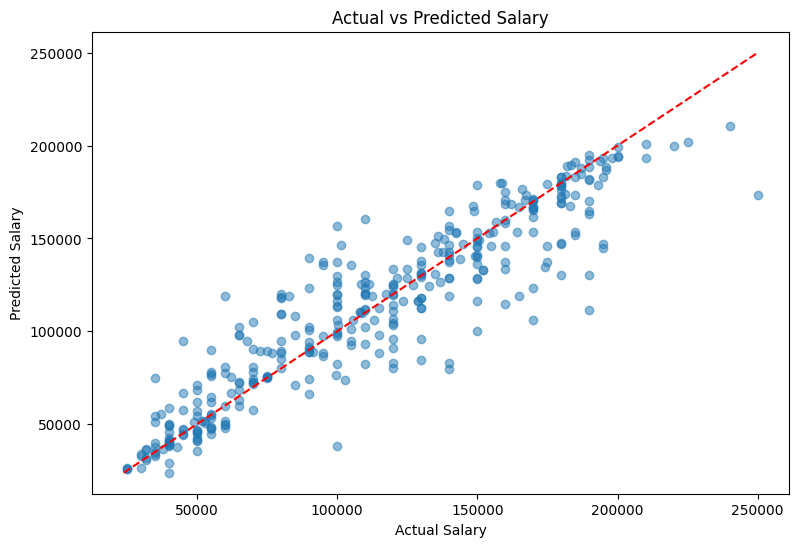

In [62]:
plt.figure(figsize=(9, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    color="red"
)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")
plt.show()

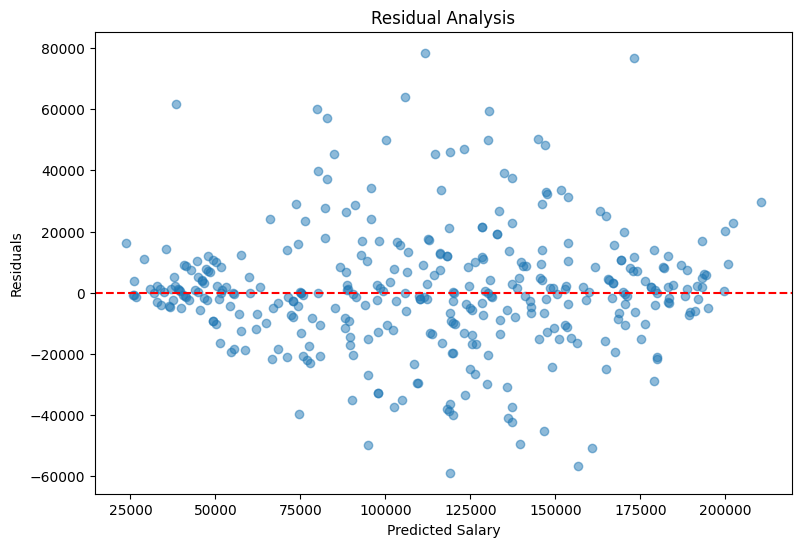

In [63]:
residuals = y_test - y_pred

plt.figure(figsize=(9, 6))

plt.scatter(y_pred, residuals, alpha=0.5)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Salary")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.show()

## CatBoost Regressor

CatBoost Modelinin Eğitilmesi

Bu modelde veriler kategorik olarak verildiği için CatBoost'un kendi kategorik işleme algoritması kullanıldı. <br>
Ön işleme adımları atlanarak modelin eğitilmesi sağlandı. <br>

Modelde iterasyon sayısı 5000 olarak ayarlandı. Bu değer modelin kaç kere veriyi işleyeceğini belirler. <br>
learning_rate=0.1 olarak ayarlandı. Bu değer modelin öğrenme hızını belirler. İterasyon sayısının yüksek tutulup learning_rate'in düşük tutulması modelin daha iyi eğitilmesini sağladığı gözlemlendi. <br>


In [64]:
cat_features_list = ['gender', 'education_level', 'job_title']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.columns.tolist())


model = CatBoostRegressor(
    iterations=5000,           
    learning_rate=0.01,       
    depth=8,                  
    cat_features=cat_features_list, 
    verbose=100              
)

X_train = X_train.copy()
X_test = X_test.copy()

for column in cat_features_list:
    X_train[column] = (
        X_train[column]
        .astype("object")
        .where(X_train[column].notna(), "__missing__")
        .astype(str)
    )
    X_test[column] = (
        X_test[column]
        .astype("object")
        .where(X_test[column].notna(), "__missing__")
        .astype(str)
    )

numeric_columns_catboost = [
    column for column in X_train.columns
    if column not in cat_features_list
]

for column in numeric_columns_catboost:
    X_train[column] = pd.to_numeric(X_train[column], errors="coerce")
    X_test[column] = pd.to_numeric(X_test[column], errors="coerce")

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"\n Model Performance:")
print(f"Mean Absolute Error (MAE): ${mae:.2f}")
print(f"Mean Squared Error (MSE): ${mse:.2f}")
print(f"R-Squared (R2): {r2:.4f}")


['age', 'gender', 'education_level', 'job_title', 'years_of_experience']
0:	learn: 51194.1748261	total: 59.2ms	remaining: 4m 55s
100:	learn: 30095.2595947	total: 194ms	remaining: 9.41s
200:	learn: 21883.2021323	total: 329ms	remaining: 7.85s
300:	learn: 18989.3626164	total: 478ms	remaining: 7.46s
400:	learn: 17530.0973444	total: 642ms	remaining: 7.37s
500:	learn: 16695.8015304	total: 805ms	remaining: 7.23s
600:	learn: 15997.6177666	total: 964ms	remaining: 7.05s
700:	learn: 15496.4450459	total: 1.15s	remaining: 7.06s
800:	learn: 15031.2668992	total: 1.47s	remaining: 7.72s
900:	learn: 14606.4597731	total: 1.62s	remaining: 7.39s
1000:	learn: 14264.5455626	total: 1.75s	remaining: 6.99s
1100:	learn: 13784.6374632	total: 1.9s	remaining: 6.74s
1200:	learn: 13412.6722264	total: 2.06s	remaining: 6.53s
1300:	learn: 13052.9767078	total: 2.21s	remaining: 6.29s
1400:	learn: 12739.2704767	total: 2.35s	remaining: 6.05s
1500:	learn: 12451.4074754	total: 2.51s	remaining: 5.85s
1600:	learn: 12199.1359375

CatBoost Model Performance:
--------------------------------
Mean Absolute Error (MAE): $11341.92 <br>
Mean Squared Error (MSE): $264654904.37 <br>
R-Squared (R2): 0.9006 <br><br><br>

Modelin R² değeri 0.9006 çıktı. Bu değer modelin veriyi açıklama oranını gösterir. Diğer iki modele göre çok daha yüksek bir değer. <br><br>
MAE değeri 11341.92 çıktı. Bu da yine aynı şekilde diğer iki modele göre çok daha düşük bir değer. <br><br>
